# Longtest: MCP path — biexponential blind fit (agent)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

rng = np.random.default_rng(42)
truth = {"A1": 0.9, "A2": 0.35, "k1": 0.7, "k2": 0.15, "sigma": 0.02}
t = np.linspace(0.0, 6.0, 300)
noiseless = truth["A1"] * np.exp(-truth["k1"] * t) + truth["A2"] * np.exp(-truth["k2"] * t)
y = noiseless + truth["sigma"] * rng.standard_normal(t.shape)
print("t.shape", t.shape, "y.shape", y.shape)
print("y[:5]", np.round(y[:5], 4))


t.shape (300,) y.shape (300,)
y[:5] [1.2561 1.2156 1.238  1.2285 1.1576]


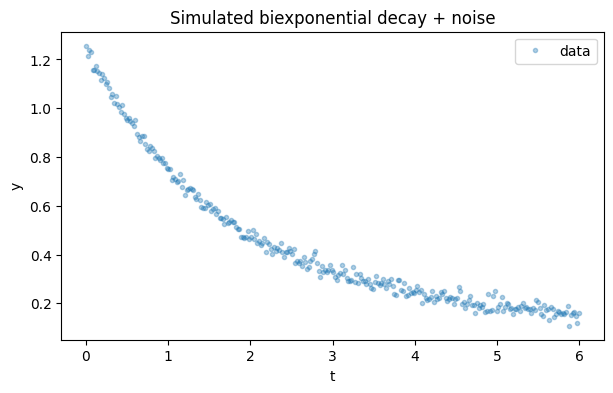

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, y, ".", alpha=0.35, label="data")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title("Simulated biexponential decay + noise")
ax.legend()
plt.show()


A1: truth=0.9  fit=0.912771
k1: truth=0.7  fit=0.695962
A2: truth=0.35  fit=0.338197
k2: truth=0.15  fit=0.145126


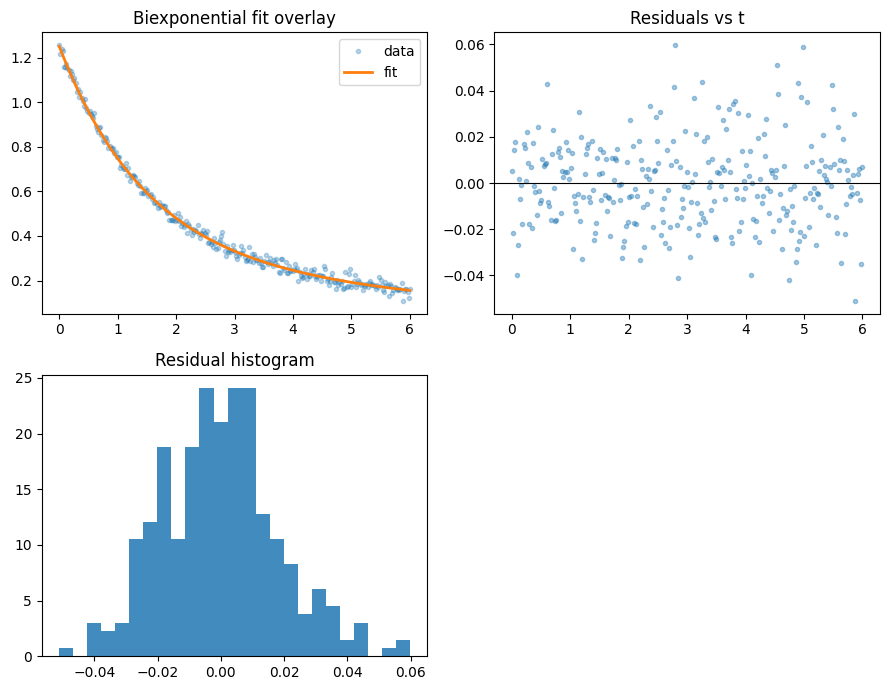

In [3]:
def biexp(tt, A1, k1, A2, k2):
    return A1 * np.exp(-k1 * tt) + A2 * np.exp(-k2 * tt)

p0 = (1.0, 0.5, 0.5, 0.3)
bounds = ([0, 0, 0, 0], [np.inf, np.inf, np.inf, np.inf])
popt, pcov = curve_fit(biexp, t, y, p0=p0, bounds=bounds, maxfev=20000)
names = ["A1", "k1", "A2", "k2"]
truth_vec = [truth["A1"], truth["k1"], truth["A2"], truth["k2"]]
for nm, tv, est in zip(names, truth_vec, popt):
    print(f"{nm}: truth={tv:.6g}  fit={est:.6g}")

yhat = biexp(t, *popt)
res = y - yhat

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes[0, 0].plot(t, y, ".", alpha=0.3, label="data")
axes[0, 0].plot(t, yhat, "-", lw=2, label="fit")
axes[0, 0].legend()
axes[0, 0].set_title("Biexponential fit overlay")
axes[0, 1].plot(t, res, ".", alpha=0.4)
axes[0, 1].axhline(0, color="k", lw=0.8)
axes[0, 1].set_title("Residuals vs t")
axes[1, 0].hist(res, bins=25, density=True, alpha=0.85)
axes[1, 0].set_title("Residual histogram")
axes[1, 1].axis("off")
plt.tight_layout()
plt.show()


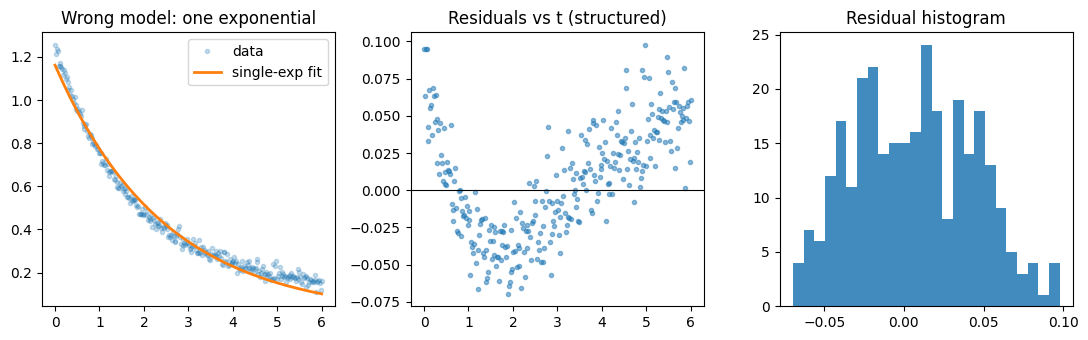

Residuals swing from positive at small t to negative at large t — missing the slow tail forces the mono-exponential to compromise across time scales.


In [4]:
def monoexp(tt, A, k):
    return A * np.exp(-k * tt)

p_mono, _ = curve_fit(monoexp, t, y, p0=(1.2, 0.4), maxfev=20000)
ym = monoexp(t, *p_mono)
res_m = y - ym

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].plot(t, y, ".", alpha=0.25, label="data")
axes[0].plot(t, ym, "-", lw=2, label="single-exp fit")
axes[0].legend()
axes[0].set_title("Wrong model: one exponential")
axes[1].plot(t, res_m, ".", alpha=0.5)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Residuals vs t (structured)")
axes[2].hist(res_m, bins=25, alpha=0.85)
axes[2].set_title("Residual histogram")
plt.tight_layout()
plt.show()

print(
    "Residuals swing from positive at small t to negative at large t —"
    " missing the slow tail forces the mono-exponential to compromise"
    " across time scales."
)


In [5]:
# Optimizer / starting-point sensitivity (same bounds as biexp fit)
bounds = ([0, 0, 0, 0], [np.inf, np.inf, np.inf, np.inf])
p_far = curve_fit(biexp, t, y, p0=(0.1, 0.05, 5.0, 2.0), bounds=bounds, maxfev=50000)[0]
p_near = curve_fit(biexp, t, y, p0=(1.0, 0.5, 0.5, 0.3), bounds=bounds, maxfev=50000)[0]


def norm_pairs(p):
    """Order (A,k) pairs by decreasing k so swapped exponentials compare cleanly."""
    A1, k1, A2, k2 = p
    if k1 >= k2:
        return np.array([A1, k1, A2, k2])
    return np.array([A2, k2, A1, k1])


print("far p0 (sorted pairs):", np.round(norm_pairs(p_far), 4))
print("sensible p0 (sorted pairs):", np.round(norm_pairs(p_near), 4))


far p0 (sorted pairs): [0.9128 0.696  0.3382 0.1451]
sensible p0 (sorted pairs): [0.9128 0.696  0.3382 0.1451]


## Conclusions

- The simulated signal matches \(y = A_1 e^{-k_1 t} + A_2 e^{-k_2 t}\) plus Gaussian noise; **four-parameter** `curve_fit` recovers rates and amplitudes close to truth, and residuals versus \(t\) look unstructured.
- Fitting only **one** exponential forces a single decay rate to approximate both components; **residuals versus time** show a smooth drift (often high early, low late), which is the hallmark of **model misspecification**, not only heavier-tailed noise.
- The residual **histogram** under the wrong model can deviate from symmetric Gaussian shape because deterministic mismatch dominates.
- The two exponentials are **exchangeable** (swap \((A_1,k_1)\) with \((A_2,k_2)\)); compare fits after sorting \((A,k)\) pairs by rate.
- Nonlinear least squares still benefits from sensible \(p_0\); terrible guesses can permute labels or converge slowly even when the minimum is eventually found.
